In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, median_absolute_error

In [ ]:
df=pd.read_csv("data/car_details.csv")
df

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner
...,...,...,...,...,...,...,...,...
4335,Hyundai i20 Magna 1.4 CRDi (Diesel),2014,409999,80000,Diesel,Individual,Manual,Second Owner
4336,Hyundai i20 Magna 1.4 CRDi,2014,409999,80000,Diesel,Individual,Manual,Second Owner
4337,Maruti 800 AC BSIII,2009,110000,83000,Petrol,Individual,Manual,Second Owner
4338,Hyundai Creta 1.6 CRDi SX Option,2016,865000,90000,Diesel,Individual,Manual,First Owner


In [ ]:
df["brand"] = df["name"].str.split().str[0]
df["model"] = df["name"].str.split().str[1]

In [ ]:
df['model'].value_counts()


,count
model,
Swift,320
Alto,258
Wagon,164
i20,132
Verna,129
...,...
Spacio,1
RS7,1
GLS,1


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
 8   brand          4340 non-null   object
 9   model          4340 non-null   object
dtypes: int64(3), object(7)
memory usage: 339.2+ KB


In [ ]:
df.drop_duplicates()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,brand,model
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner,Maruti,800
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner,Maruti,Wagon
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner,Hyundai,Verna
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner,Datsun,RediGO
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner,Honda,Amaze
...,...,...,...,...,...,...,...,...,...,...
4335,Hyundai i20 Magna 1.4 CRDi (Diesel),2014,409999,80000,Diesel,Individual,Manual,Second Owner,Hyundai,i20
4336,Hyundai i20 Magna 1.4 CRDi,2014,409999,80000,Diesel,Individual,Manual,Second Owner,Hyundai,i20
4337,Maruti 800 AC BSIII,2009,110000,83000,Petrol,Individual,Manual,Second Owner,Maruti,800
4338,Hyundai Creta 1.6 CRDi SX Option,2016,865000,90000,Diesel,Individual,Manual,First Owner,Hyundai,Creta


In [ ]:
df.describe()

,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


In [ ]:
q1 = df['km_driven'].quantile(0.35)
q2 = df['km_driven'].quantile(0.65)
iqr = q2-q1
low = q1 - 1.5*iqr
high = q2 +1.5*iqr

df = df[(df['km_driven'] >= max(0,low)) & (df['km_driven'] <= high)]
df.describe()

,year,selling_price,km_driven
count,4039.000000,4.039000e+03,4039.000000
mean,2013.249319,5.113044e+05,58007.461500
std,4.244506,5.913145e+05,32158.422983
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.100000e+05,30550.000000
50%,2014.000000,3.650000e+05,55340.000000
75%,2017.000000,6.000000e+05,80000.000000
max,2020.000000,8.900000e+06,121764.000000


<Axes: xlabel='selling_price', ylabel='Count'>

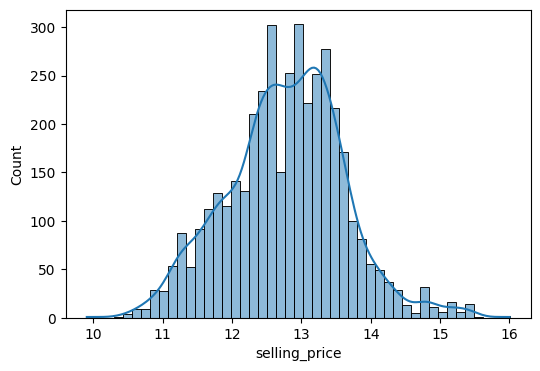

In [ ]:
plt.figure(figsize=(6,4))
sns.histplot(np.log1p(df["selling_price"]), kde=True)

In [ ]:
X.columns

Index(['year', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner',
       'brand', 'model'],
      dtype='object')

In [ ]:
X=df.drop(columns=['name','selling_price'])
y=np.log1p(df['selling_price'])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

cat_cols=['fuel', 'seller_type', 'transmission', 'owner',
       'brand', 'model']
num_cols=['year', 'km_driven']

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10),
     cat_cols),
    ("num", StandardScaler(), num_cols),
])

models = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.001),
    "RandomForest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "GradientBoosting": GradientBoostingRegressor(random_state=42),
}

results = []
for name, model in models.items():
    pipe = Pipeline([
        ("prep", preprocess),      # same preprocessing sab ke liye
        ("model", model),
    ])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)

    actual_price = np.expm1(y_test)    # log se wapas asli price
    pred_price = np.expm1(pred)

    results.append({
        "model": name,
        "R2 (log)": r2_score(y_test, pred),
        "MAE": mean_absolute_error(actual_price, pred_price),
        "MedAE": median_absolute_error(actual_price, pred_price),
    })

pd.DataFrame(results).sort_values("MAE")

,model,R2 (log),MAE,MedAE
3,RandomForest,0.885227,86465.369477,40753.912171
1,Ridge,0.882941,95427.894476,46245.124077
0,LinearRegression,0.882463,97362.099137,48017.199602
2,Lasso,0.872545,101783.416052,51826.359272
4,GradientBoosting,0.861494,112159.618878,57621.945519
